# İstatistik

İstatistik data science'ın bilim, ml'in öğrenme aşamasıdır
İstatistik olmadan data science'da en fazla data lab assistant olursun

### Örnek Teorisi

Büyük bir populasyondan bu popülasyonu temsil eden yansız bir şekilde bir örnek alt küme seçtiğimizde bunların dağılımını incelemedir.

In [2]:
import numpy as np

In [3]:
population = np.random.randint(0, 80, 100000)
population[0:10]

array([38,  2,  3, 67,  7, 55, 22, 67, 33, 47], dtype=int32)

#### Örneklem Seçimi

In [17]:
np.random.seed(61) #oluşturduğumuz random'ın her seferinde aynı şeyi getirmesini sağlar
orneklem = np.random.choice(a = population, size = 100)
orneklem[0:10]

array([60, 17, 26, 20, 10, 79, 32, 22, 58, 46], dtype=int32)

In [18]:
print(orneklem.mean())

38.98


In [19]:
print(population.mean())

39.45313


#### Örneklem Dağılımı

In [21]:
np.random.seed(61)
orneklem0 = np.random.choice(a = population, size = 100)
orneklem1 = np.random.choice(a = population, size = 100)
orneklem2 = np.random.choice(a = population, size = 100)
orneklem3 = np.random.choice(a = population, size = 100)
orneklem4 = np.random.choice(a = population, size = 100)
orneklem5 = np.random.choice(a = population, size = 100)
orneklem6 = np.random.choice(a = population, size = 100)
orneklem7 = np.random.choice(a = population, size = 100)
orneklem8 = np.random.choice(a = population, size = 100)
orneklem9 = np.random.choice(a = population, size = 100)
orneklem0 = np.random.choice(a = population, size = 100)

In [23]:
(orneklem1.mean() + orneklem2.mean() + orneklem3.mean() + orneklem4.mean() + orneklem5.mean() 
+ orneklem6.mean() + orneklem7.mean() + orneklem8.mean() + orneklem9.mean() + orneklem0.mean() )  / 10

np.float64(39.395)

## Betimsel İstatistikler

In [24]:
import seaborn as sns
tips = sns.load_dataset("tips")
df = tips.copy()
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


In [28]:
import researchpy as rp
rp.summary_cont(df[["total_bill","size","tip"]])

,Variable,N,Mean,SD,SE,95% Conf.,Interval
0,total_bill,244.0,19.7859,8.9024,0.5699,18.6633,20.9086
1,size,244.0,2.5697,0.9511,0.0609,2.4497,2.6896
2,tip,244.0,2.9983,1.3836,0.0886,2.8238,3.1728


In [29]:
rp.summary_cat(df[["smoker","sex","day","time"]])

,Variable,Outcome,Count,Percent
0,smoker,No,151,61.89
1,,Yes,93,38.11
2,sex,Male,157,64.34
3,,Female,87,35.66
4,day,Sat,87,35.66
5,,Sun,76,31.15
6,,Thur,62,25.41
7,,Fri,19,7.79
8,time,Dinner,176,72.13
9,,Lunch,68,27.87


### Korelasyon ve Koveryans

In [ ]:
# Kovaryans: İki değişken aynı yönde mi, zıt yönde mi değişiyor?
# Korelasyon: İki değişken hangi yönde ve ne kadar güçlü doğrusal ilişkiye sahip?
# Korelasyon sıfır olsa dahi doğrusal olmayan bir ilişki bulunabilir

In [ ]:
'''
Yüksek korelasyon, özelliklerden birini mutlaka silmemiz gerektiği anlamına gelmez.
Ayrıca korelasyon, bir özelliğin model için ne kadar faydalı olduğunu tek başına belirlemez.
'''

In [33]:
df[["tip","total_bill"]].corr()

,tip,total_bill
tip,1.000000,0.675734
total_bill,0.675734,1.000000


In [32]:
df[["tip","total_bill"]].cov()

,tip,total_bill
tip,1.914455,8.323502
total_bill,8.323502,79.252939


### Güven Aralığı

Standart sapma: Verilerin kendi aralarında ne kadar dağıldığını gösterir.
Standart hata: Örneklemden hesaplanan ortalama tahmininin ne kadar değişken olduğunu gösterir.
Güven aralığı: Bilinmeyen popülasyon parametresini tahmin ederken bu belirsizliği bir aralıkla ifade eder.

In [35]:
import numpy as np
import statsmodels.stats.api as sms

In [36]:
prices = np.random.randint(10, 110, 1000)
prices.mean()

np.float64(58.955)

In [ ]:
sms.DescrStatsW(prices).tconfint_mean(alpha = 0.05)
# İnsanların sadece %5'i bu aralıkta dışında bir sayı seçmiştir

(np.float64(57.17141070327065), np.float64(60.738589296729344))

## Olasılık ve Olasılık Dağılımları

In [ ]:
#Olasılık, bir olayın gerçekleşme ihtimalini sayısal olarak ifade eder.
#Random variable (rastsal değişken), rastgele bir deneyin sonucunu sayıyla ifade eden değişkendir. Coinde yazının 1, turanın 0'la eşleşmesi gibi.
#Olasılık dağılımı random variable'nin hangi değeri ne kadar olasılıkla aldığıdır, yani tüm değerlerin olasılığını belirtir.
#Olasılık fonksiyonu: Belirli bir değer için olasılığı matematiksel olarak hesaplamamızı sağlar,
#discrete değişkenler için kullandığımız fonksiyona Probability Mass Function (PMF) denir.
#continous değişkenlerde PDF kullanılır, PDF'in belirli bir noktadaki değeri doğrudan olasılık değildir. Olasılık, bir aralık altında kalan alanla bulunur.

In [ ]:
'''
P(Y=1|X=x)
Bu ifadenin anlamı: Özellikleri x olan bir kişinin hasta olma olasılığı nedir?
Buradaki | işareti "verildiğinde" anlamındadır. Yani koşullu olasılıktan bahsediyoruz.

Örneğin modelin çıktısı:P(Y=1 | X=x)=0.85 olabilir.
Bu, modelin ilgili özelliklere sahip biri için %85 hastalık olasılığı tahmin ettiğini gösterir.

Burada önemli bir fark var: P(Y=1)
Toplumdaki genel hastalık olasılığıdır.

P(Y=1 | X=x) İse kişinin özelliklerine bağlı hastalık olasılığıdır.

!ML modellerinin önemli avantajı, genel bir oran yerine bireyin özelliklerine koşullu tahminler üretmesidir.
'''

In [ ]:
'''
Dağılımın nasıl olduğu nasıl bilinir?
    Dağılım görselleştirilir ve görsel tekniklerle incelenir normal dağıldığı gözüküyor olabilir veya testler yapılabilir.
'''

In [52]:
#Discrete Olasılık Dağılımları : Bernoulli, Binom, Poisson
#Continours Olasılık Dağılımları : Uniform, Normal, Üstel Dağılım

### Bernoulli Dağılımı

In [ ]:
#İki sonuçlu discrete sonuçlu olaylarla ilgilendiğimizde kullandığımız dağılımdır

${\displaystyle f(k;p)=p^{k}(1-p)^{1-k}\quad {\text{for }}k\in \{0,1\}}$


${\displaystyle \operatorname {E} \left(X\right)=p}$

$\operatorname {Var} [X]=pq=p(1-p)$

In [58]:
from scipy.stats import bernoulli

In [ ]:
p = 0.6 #bunu bizim eğittiğimiz model öğrenecek normalde
rv = bernoulli(p)

In [61]:
rv.pmf(k = 0)

np.float64(0.4000000000000001)

In [62]:
rv.pmf(k = 1)

np.float64(0.6)

### Büyük Sayılar Yasası

**Bir rassal değişkenin uzun vadeli kararlılığını tanımlayan olasılık teoremidir.**

**Bernoulli dağılımı bize p değerinin kaç olması gerektiğini söylemez. Biz p değerini teorik varsayımlardan, geçmiş verilerden veya deneylerden belirleriz. Bernoulli dağılımı da bu olasılığı kullanarak 0 ve 1 sonuçlarını modeller.**

In [64]:
import numpy as np
rng = np.random.RandomState(123)
for i in np.arange(1,21):
    deney_sayisi = 2**i
    yazi_turalar = rng.randint(0, 2, size = deney_sayisi)
    yazi_olasiliklari = np.mean(yazi_turalar)
    print("Atış Sayısı:",deney_sayisi,"---",'Yazı Olasılığı: %.2f' % (yazi_olasiliklari * 100))

Atış Sayısı: 2 --- Yazı Olasılığı: 50.00
Atış Sayısı: 4 --- Yazı Olasılığı: 0.00
Atış Sayısı: 8 --- Yazı Olasılığı: 62.50
Atış Sayısı: 16 --- Yazı Olasılığı: 43.75
Atış Sayısı: 32 --- Yazı Olasılığı: 46.88
Atış Sayısı: 64 --- Yazı Olasılığı: 56.25
Atış Sayısı: 128 --- Yazı Olasılığı: 50.78
Atış Sayısı: 256 --- Yazı Olasılığı: 52.73
Atış Sayısı: 512 --- Yazı Olasılığı: 52.93
Atış Sayısı: 1024 --- Yazı Olasılığı: 50.20
Atış Sayısı: 2048 --- Yazı Olasılığı: 48.58
Atış Sayısı: 4096 --- Yazı Olasılığı: 49.49
Atış Sayısı: 8192 --- Yazı Olasılığı: 49.58
Atış Sayısı: 16384 --- Yazı Olasılığı: 49.96
Atış Sayısı: 32768 --- Yazı Olasılığı: 50.00
Atış Sayısı: 65536 --- Yazı Olasılığı: 49.68
Atış Sayısı: 131072 --- Yazı Olasılığı: 49.97
Atış Sayısı: 262144 --- Yazı Olasılığı: 50.13
Atış Sayısı: 524288 --- Yazı Olasılığı: 50.01
Atış Sayısı: 1048576 --- Yazı Olasılığı: 50.09


### Binom Dağılımı

In [72]:
#Bernoulli'nin n defa gerçekleştirilmiş halidir. Yapılan deneyler bağımsız ve aynı koşullarda gerçekleştirilmelidir.

${\displaystyle f(k;n,p)={n \choose k}p^{k}(1-p)^{n-k}}$, k = 0, 1, 2, ...,n


${\displaystyle \operatorname {E} (X)=np}$


${\displaystyle \operatorname {Var} (X)=np(1-p)}$

In [73]:
from scipy.stats import binom

In [77]:
'''
Bir mecrada reklam verilecek. Reklama tıklanma ve geri dönüş sayıları optimize edilmeye çalışılıyor. Buna yönelik olarak belirli bir mecrada çeşitli
senaryolara göre reklama tıklama olasılıkları hesaplanmak isteniyor
'''
p = 0.01 #Bir kişinin reklama tıklama olaşığı
n = 100 #Reklamı 100 kişi görüyor
rv = binom(n, p)
print(rv.pmf(k = 1)) #Reklamı 100 kişi gördüğünde 1 kişinin tıklama olasılığı nedir?
print(rv.pmf(k = 5)) #Reklamı 100 kişi gördüğünde 5 kişinin tıklama olasılığı nedir?
print(rv.pmf(k = 10)) #Reklamı 100 kişi gördüğünde 10 kişinin tıklama olasılığı nedir?

0.36972963764972666
0.002897787123761478
7.006035693977194e-08


### Poisson Dağılımı

In [ ]:
#Belirli bir zaman aralığında belirli bir alanda nadiren rastlanan olayların olasılıklarını hesaplamak için kullanılır. Denemeler birbirinden bağımsız
#ve aynı koşullar altında yapılmalıdır; bu denemeler iki sonuçlu olmalıdır.
#Hata sayısı ortalama hata sayısına eşittir aslında, çünkü bu dağılımda ortalama ve varyans aynı değerdir.

In [3]:
'''
Bir sitede bir yıl süresince ölçümler yapılıyor hatalı ilan girişleri gerçekleşiyor.
ilan girişlerinde 3 hata olması, 5 hata olması, hiç hata olmaması olasılığı nedir;
dağılımın poisson olduğu biliniyor ve lambda = 0.1

Bir olayın nadir olay olarak kabul görmesi için n > 50, np<5 olmalıdır
'''

'\nBir sitede bir yıl süresince ölçümler yapılıyor hatalı ilan girişleri gerçekleşiyor.\nilan girişlerinde 3 hata olması, 5 hata olması, hiç hata olmaması olasılığı nedir;\ndağılımın poisson olduğu biliniyor ve lambda = 0.1\n\nBir olayın nadir olay olarak kabul görmesi için n > 50, np<5 olmalıdır\n'

In [81]:
from scipy.stats import poisson

In [84]:
lambda_ = 0.1
rv = poisson(mu = lambda_)
print(rv.pmf(k=0))
print(rv.pmf(k=3))
print(rv.pmf(k=5))

0.9048374180359595
0.00015080623633932676
7.54031181696634e-08


In [ ]:
'''
Modelin sana verdiği olasılık ile verdiği sınıf aynı şey değildir.
Örneğin model: P(Y=1 | X) = 0.65 tahmin etti.
Threshold 0.5 ise hasta deriz.
Threshold 0.7 ise sağlıklı deriz.

!Makine öğrenmesinde threshold, modelin kendisinden ayrı bir karar mekanizmasıdır.
'''

### Normal Dağılım

${\displaystyle f(x\mid \mu ,\sigma ^{2})={\frac {1}{\sqrt {2\pi \sigma ^{2}}}}e^{-{\frac {(x-\mu )^{2}}{2\sigma ^{2}}}}}$

* $\mu$  ortalama ya da dağılımın beklenen değeri

* ${\displaystyle \sigma }$  standart sapma

* ${\displaystyle \sigma ^{2}}$ varyans

In [ ]:
'''
Bir yatırım ya da toplantı öncesinde, yatırım toplantısı ya da herhangi bir toplantı öncesinde gelecek ay ile ilgili satışların belirli 
değerlerde gerçekleşmesi olasılıkları belirlenmek istiyor.

Dağılımın normal olduğu biliniyor.
Aylık ortalama satış sayısı 80k, standart sapması ise 50k.
Burada 90K dan fazla satış yapma olasılığı nedir?
'''

In [5]:
from scipy.stats import norm

In [7]:
#90'dan fazla olma olasılığı
1-norm.cdf(90, 80, 5)

np.float64(0.02275013194817921)

In [6]:
#70'den fazla olması
1-norm.cdf(70, 80, 5)

np.float64(0.9772498680518208)

In [8]:
#73'den az olması
norm.cdf(73, 80, 5)

np.float64(0.08075665923377107)

In [9]:
#85 ile 90 arasında olması
norm.cdf(90, 80, 5) - norm.cdf(85, 80, 5)

np.float64(0.13590512198327787)

## Hipotez Testi

In [ ]:
'''
Hipotez kuracağız, testler elde edeceğiz, bunları karşılaştıracağız, bunun üzerinde
yorumlar yapacağız ve bir çok böyle peş peşe gelen işlem yapacağız.
Fakat burada bizim için bir kestirme yol var: p-value
'''

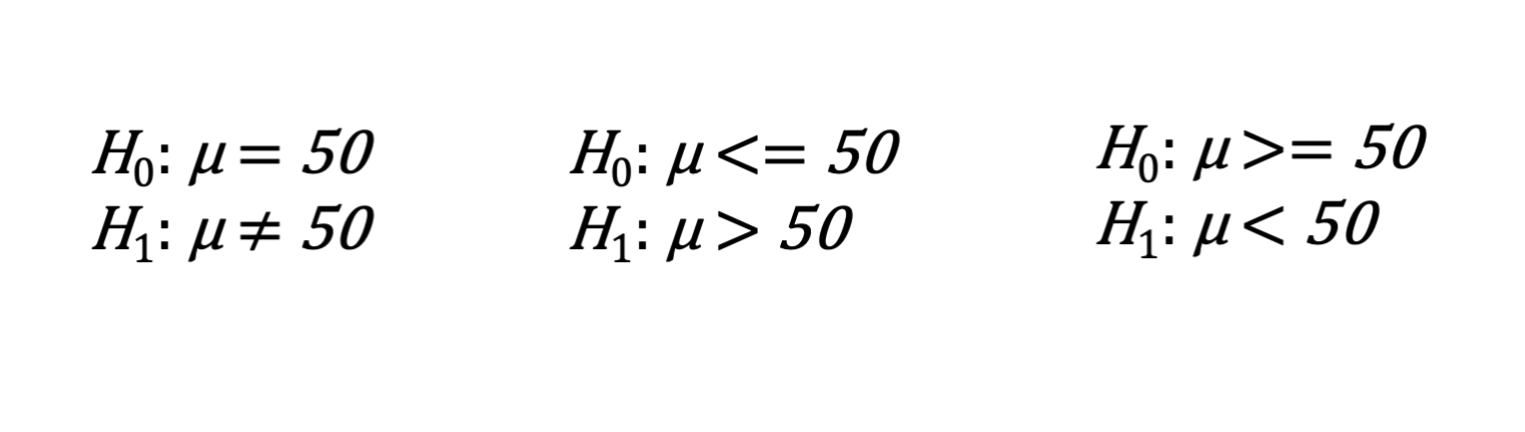

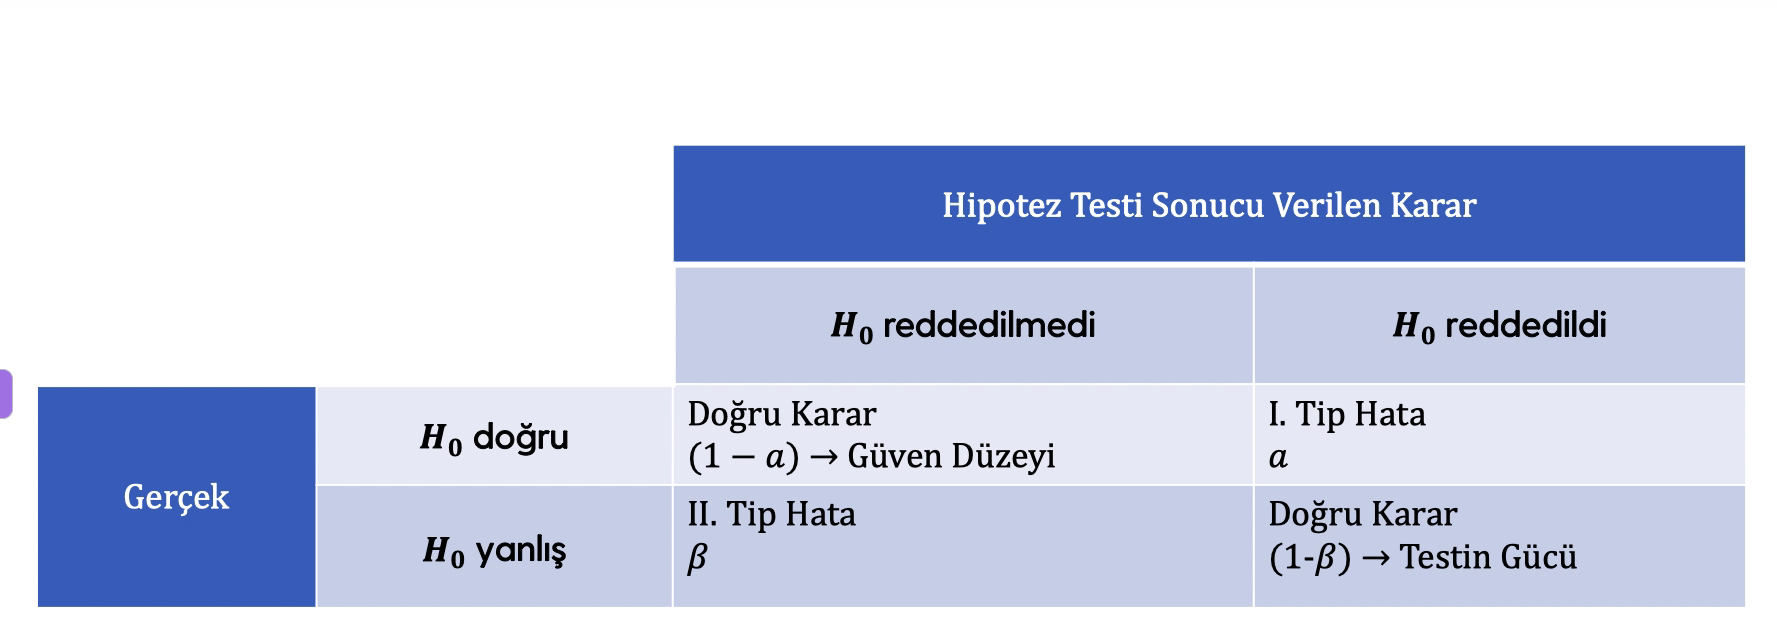

In [ ]:
'''
        Hipotez Testleri Adımları
    Adım 1 - Hipotezlerin kurulması ve yönlerinin belirlenmesi
    Adım 2 - Anlamlılık düzeyinin(kabul edilebilir hata miktarı[alpha]) ve tablo değerinin 
belirlenmesi(alpha = 0.05 kabul edilir, karşılık gelen tablo değeri[z, t, ki kare])
    Adım 3 - Test istatistiğinin belirlenmesi ve test istatistiğinin hesaplanması
    Adım 4 - Hesaplanan test istatistiği ile Alpha'ya karşılık gelen tablo değerinin karşılaştırılmasıyla H0 hipotezinin reddedilip 
reddedilemileyeceğine karar veriliyor(bu basamaklar yerine p value değeri ile de bu tabloların değerlerinin yorumlayabiliriz)
    Adım 5 - Hipotez sonuçları yorumlama

!Varsayımlarımız sağlanırsa parametrik t testlerini kullanırız, yoksa nonparametrik olanları kullanırız.

!Hipotezlerimiz hepsini iki yönlü olarak yazarız, yöne çok takılmayız.
'''

"\n        Hipotez Testleri Adımları\n    Adım 1 - Hipotezlerin kurulması ve yönlerinin belirlenmesi\n    Adım 2 - Anlamlılık düzeyinin(kabul edilebilir hata miktarı[alpha]) ve tablo değerinin \nbelirlenmesi(alpha = 0.05 kabul edilir, karşılık gelen tablo değeri[z, t, ki kare])\n    Adım 3 - Test istatistiğinin belirlenmesi ve test istatistiğinin hesaplanması\n    Adım 4 - Hesaplanan test istatistiği ile Alpha'ya karşılık gelen tablo değerinin karşılaştırılmasıyla H0 hipotezinin reddedilip \nreddedilemileyeceğine karar veriliyor(bu basamaklar yerine p value değeri ile de bu tabloların değerlerinin yorumlayabiliriz)\n    Adım 5 - Hipotez sonuçları yorumlama\n\n!Varsayımlarımız sağlanırsa parametrik t testlerini kullanırız, yoksa nonparametrik olanları kullanırız\n"

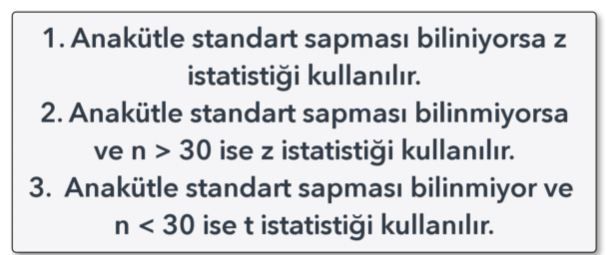  
Genelde programlama da t istatistiği kullanılır

### Tek Örneklem T Testi

In [24]:
'''
Popülasyon ortalaması ile varsayımsal bir değer arasında istatiksel olarak anlamlı bir farklılık 
olup olmadığını test etmek için kullanılan parametrik bir testtir.
'''

'\nPopülasyon ortalaması ile varsayımsal bir değer arasında istatiksel olarak anlamlı bir farklılık \nolup olmadığını test etmek için kullanılan parametrik bir testtir.\n'

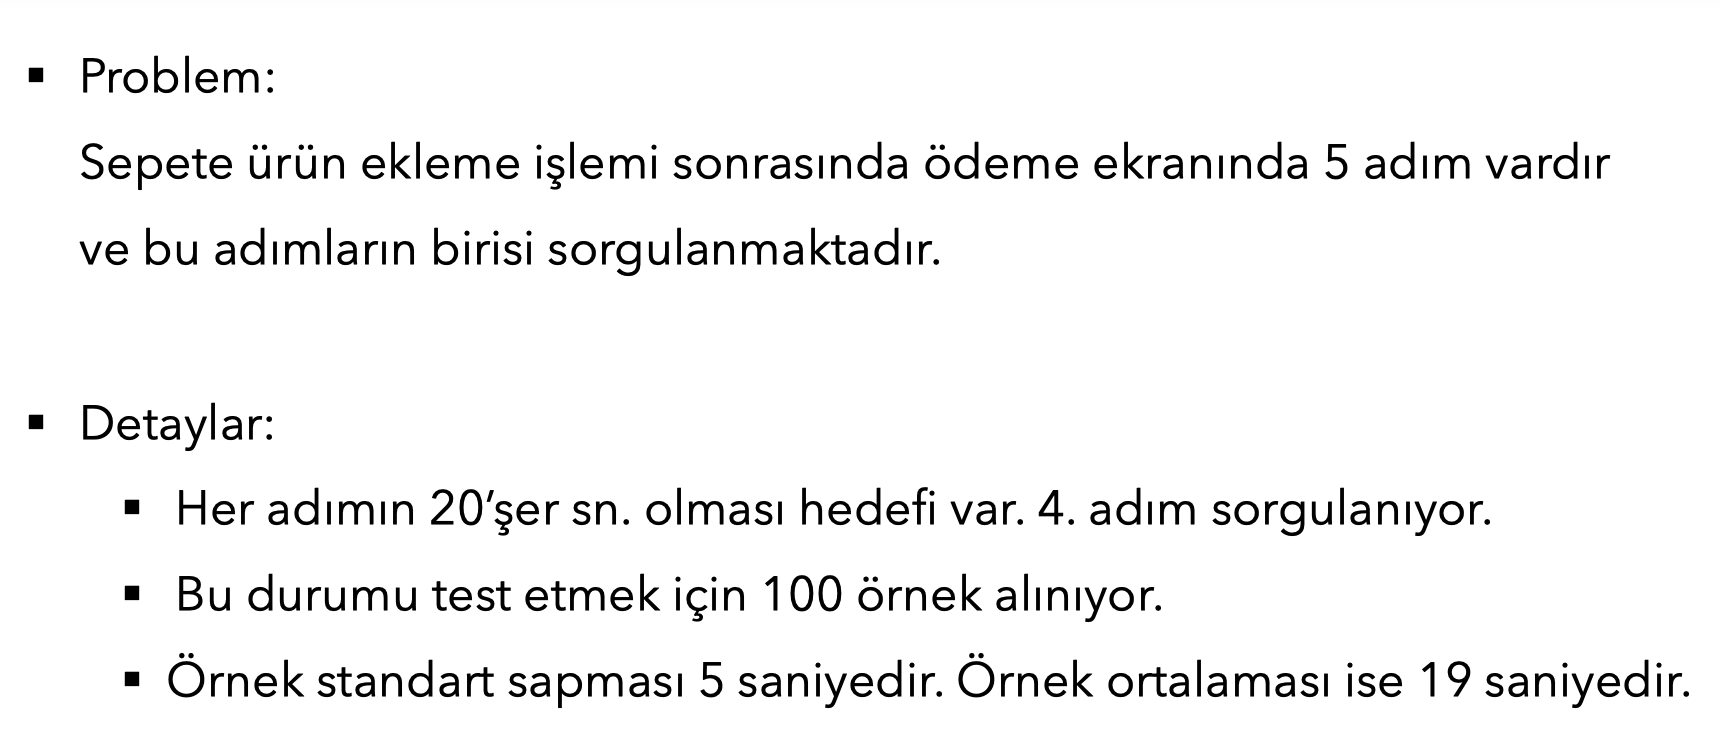
> 100 örnek çektik. Örnek ortalaması zaten 19. Neyin testini yapıyoruz?<br>
 
Ortaya çıkan bir etkinin şans eseri olup olmadığını istatistiki olarak şansa yer bırakmayacak şekilde ispat etmeye çalışıyoruz.


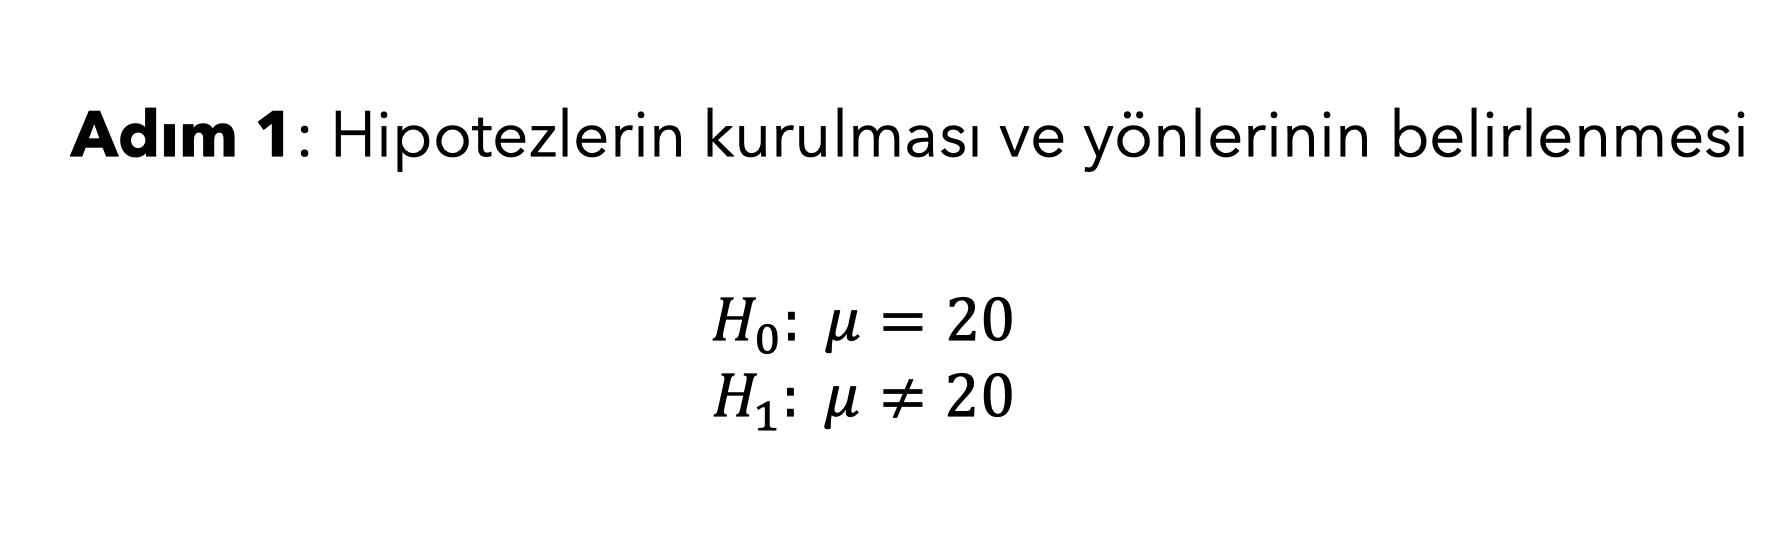

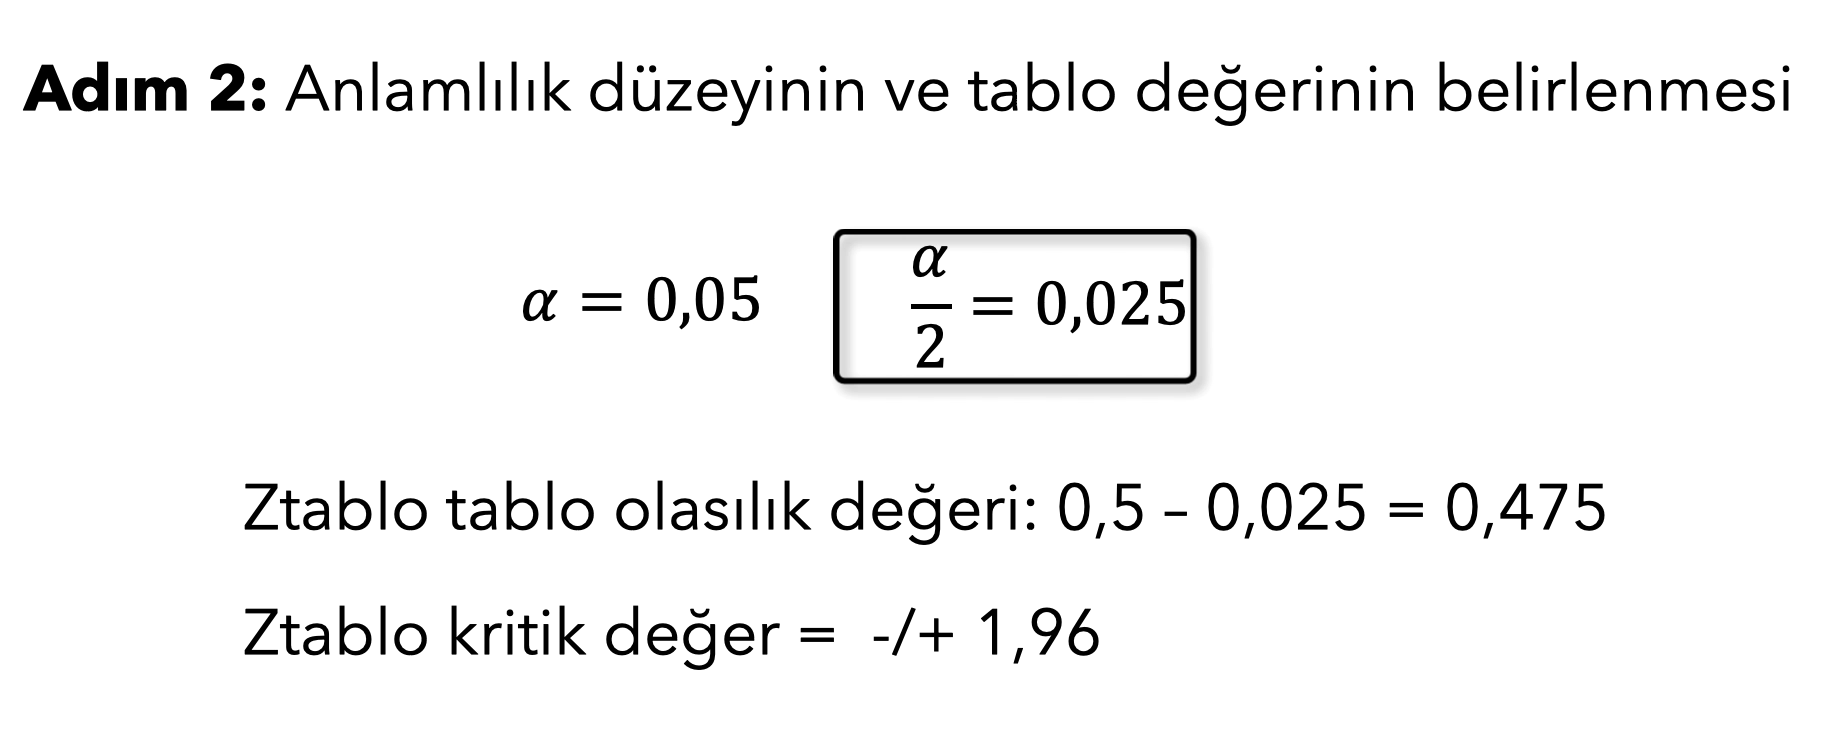
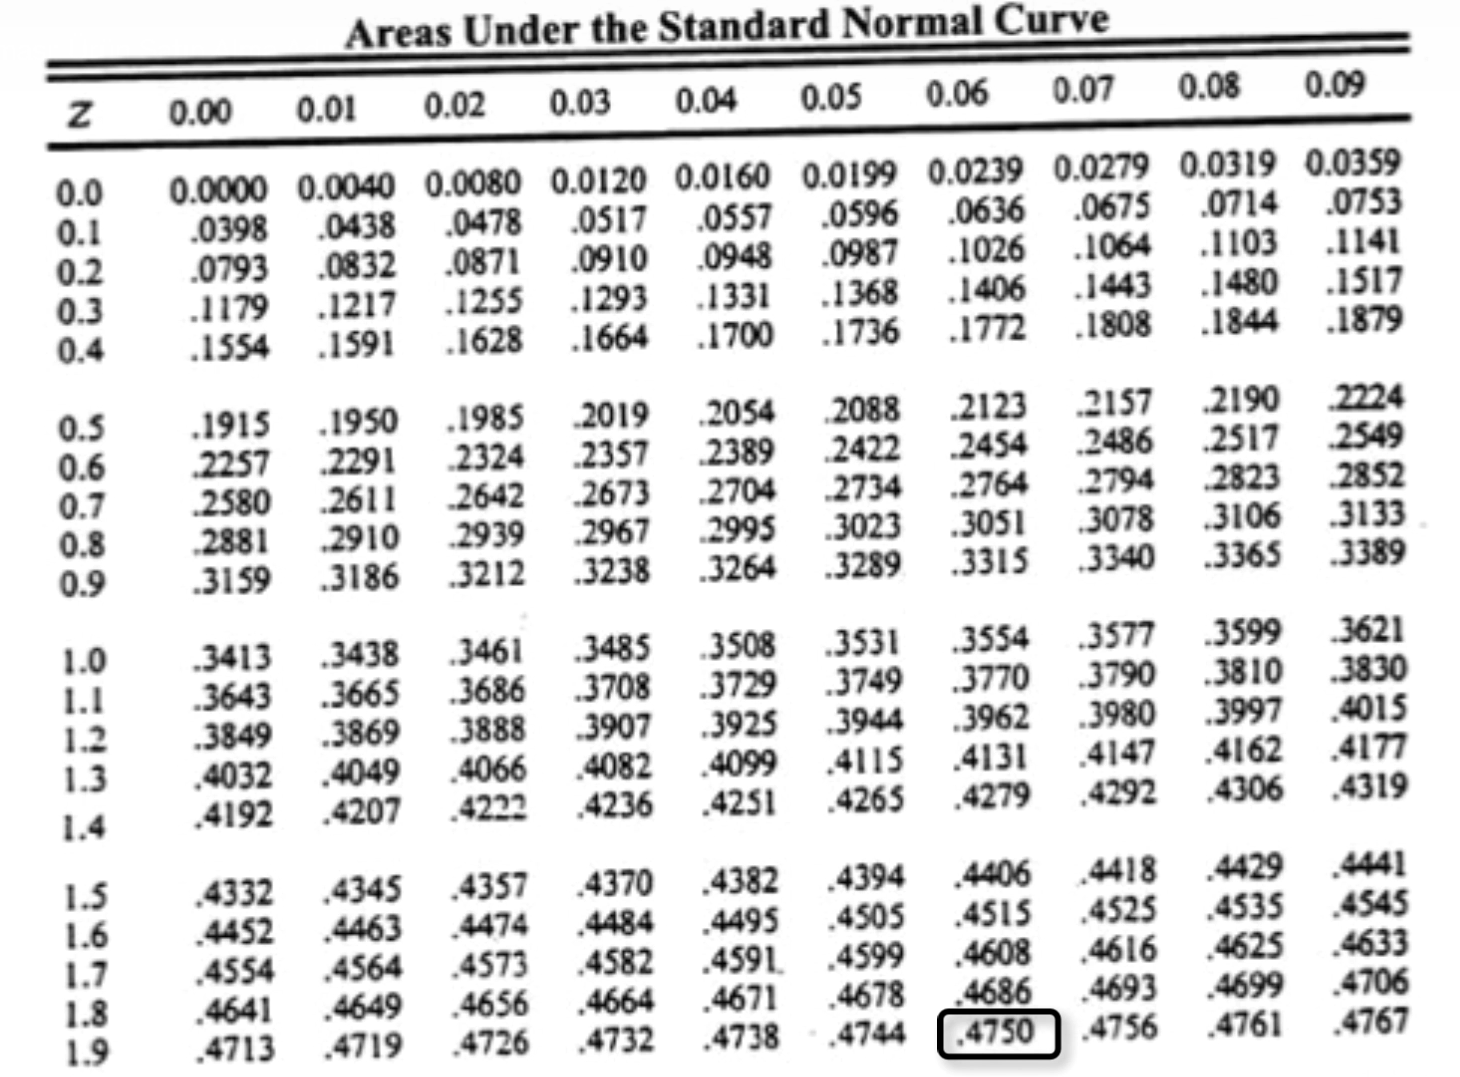

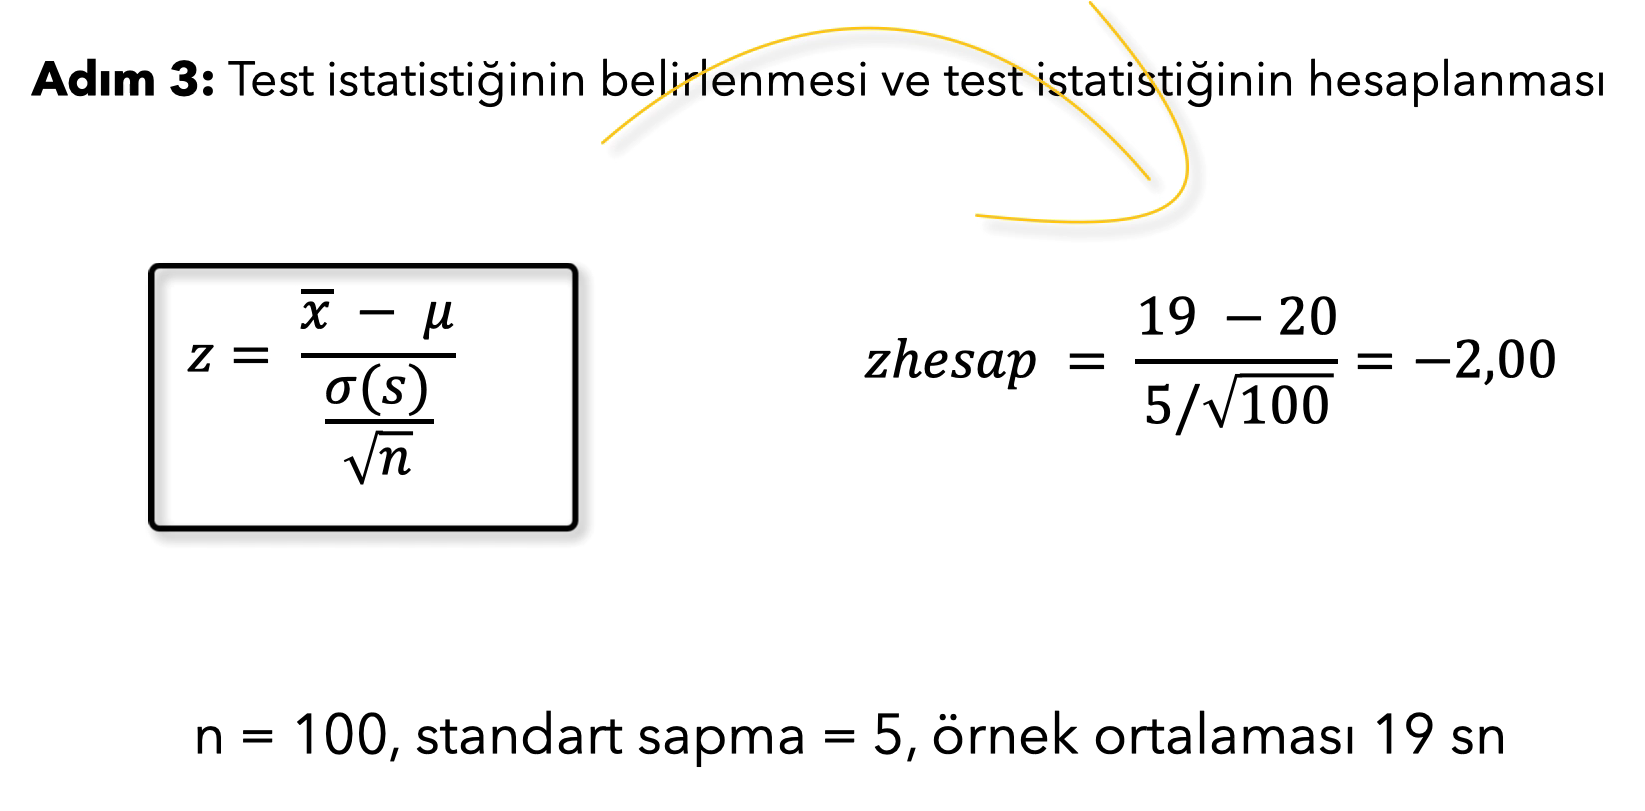

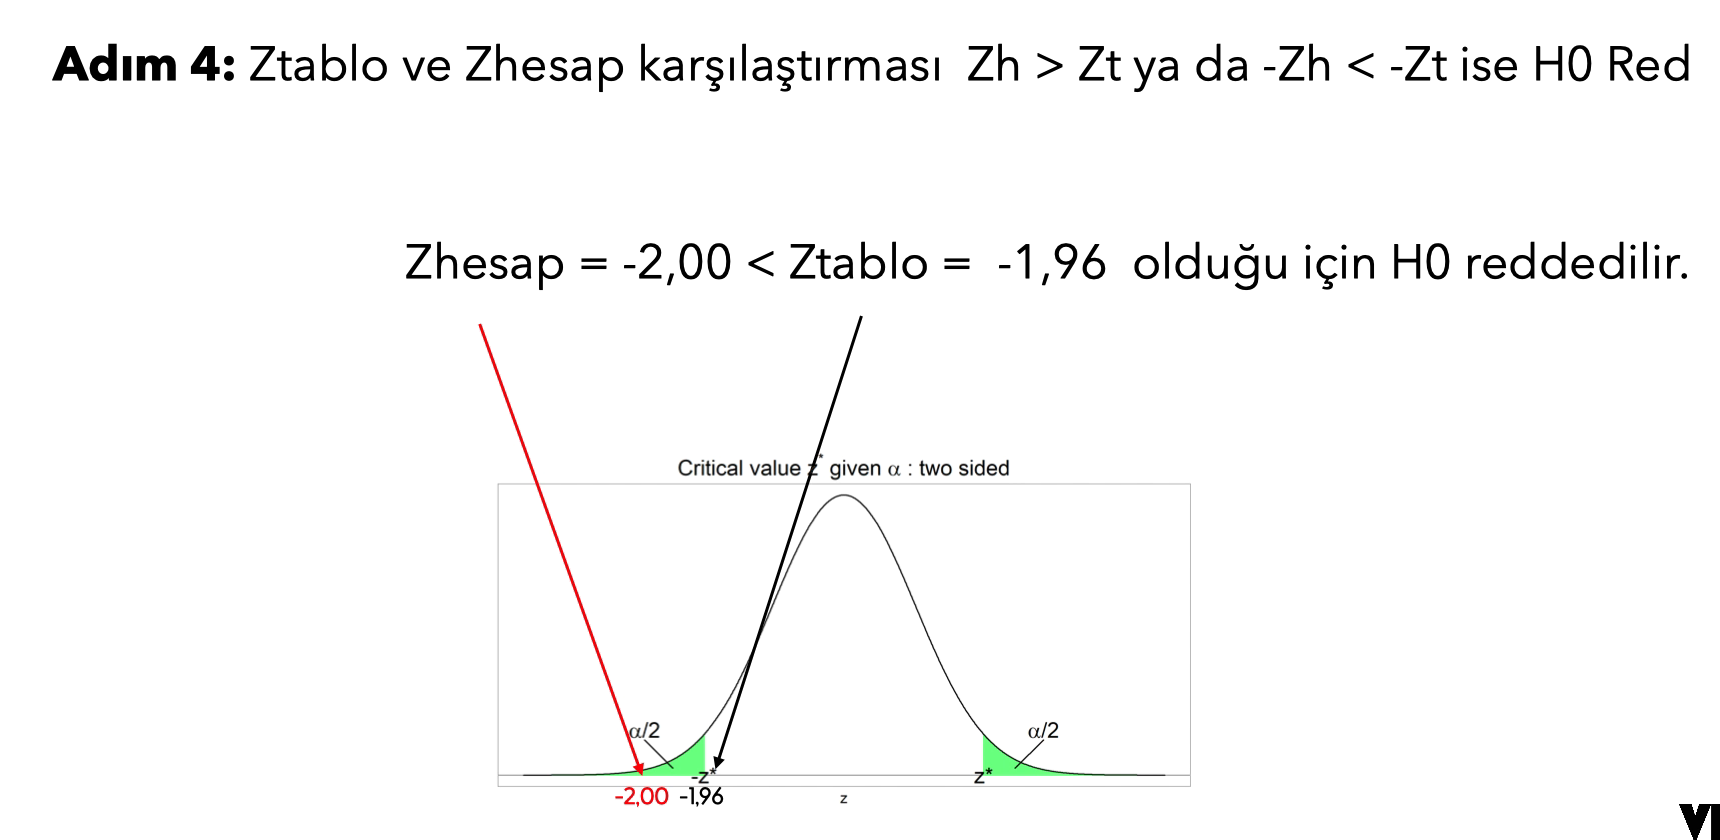

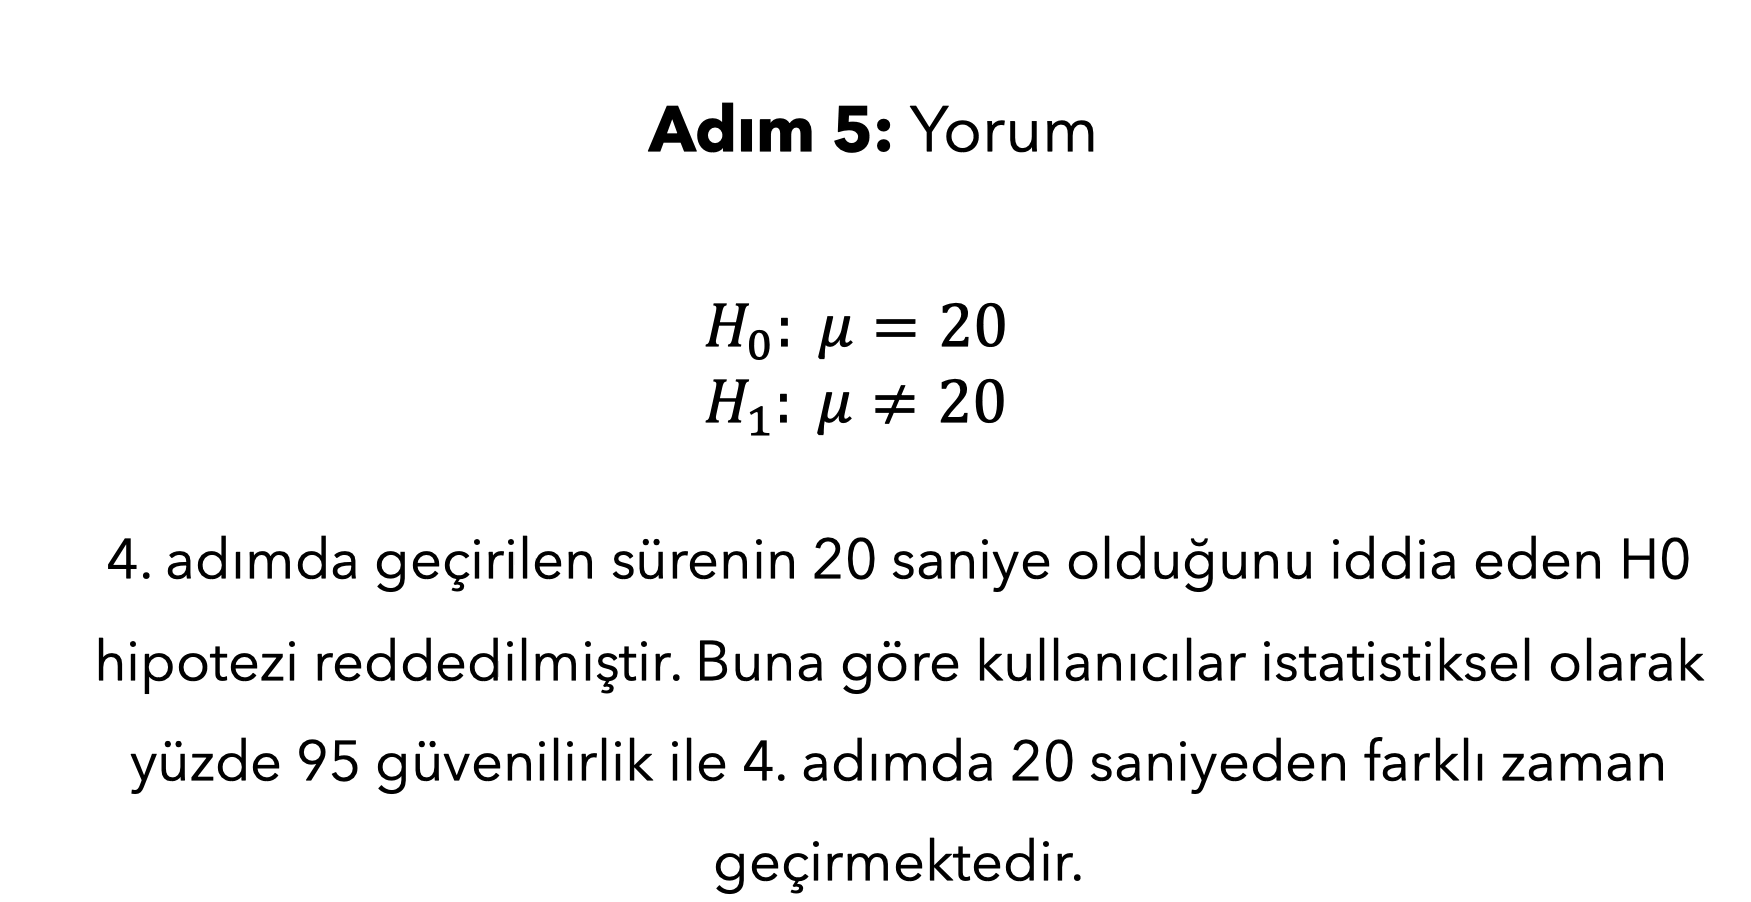

>Buna göre iş kuralları alınır, bu yöntemler sayesinde insan yanlılıkları ortadan kaldırılır

### Tek Örneklem T Testi Örnek

Örnek ortalamasına ilişkin test yapmak için kullanılır.

**Hipotezler:**

<d><i>H</i><sub>0</sub>: <i>μ</i> = <i>50</i></d>   
<d><i>H</i><sub>1</sub>: <i>μ</i> ≠ <i>50</i></d><br><br>

<d><i>H</i><sub>0</sub>: <i>μ</i> <= <i>50</i></d><br>
<d><i>H</i><sub>1</sub>: <i>μ</i> > <i>50</i></d><br><br>

<d><i>H</i><sub>0</sub>: <i>μ</i> >= <i>50</i></d><br>
<d><i>H</i><sub>1</sub>: <i>μ</i> < <i>50</i></d><br><br>




<table></table>

**Test İstatistiği:**

${\displaystyle t={\frac {{\bar {x}}-\mu _{0}}{\frac {s}{\sqrt {n}}}}}$


In [ ]:
#Sitede geçirilen vakitin ortalaması 170 saniye mi = H0 hipotezi 
import numpy as np

olcumler = np.array([17, 160, 234, 149, 145, 107, 197, 75, 201, 225, 211, 119, 
              157, 145, 127, 244, 163, 114, 145,  65, 112, 185, 202, 146,
              203, 224, 203, 114, 188, 156, 187, 154, 177, 95, 165, 50, 110, 
              216, 138, 151, 166, 135, 155, 84, 251, 173, 131, 207, 121, 120])

In [3]:
olcumler[0:10]

array([ 17, 160, 234, 149, 145, 107, 197,  75, 201, 225])

In [4]:
import scipy.stats as stats

stats.describe(olcumler)

DescribeResult(nobs=np.int64(50), minmax=(np.int64(17), np.int64(251)), mean=np.float64(154.38), variance=np.float64(2578.0363265306123), skewness=np.float64(-0.3239889727869449), kurtosis=np.float64(-0.058498234984160735))

In [13]:
stats.ttest_1samp(olcumler, popmean = 170)
#p value 0.05'den küçüktür dolayısıyla H0 reddedilir, sitede geçirilen vakit 170 saniyeden farklıdır
#Bu sonuca gitmeden önce bu tek örneklem T testini kullanmadan önce kontrol etmemiz gereken bir normallik varsayımı bulunmakta

TtestResult(statistic=np.float64(-2.1753117985877966), pvalue=np.float64(0.034460415195071474), df=np.int64(49))

#### Normallik Varsayımı

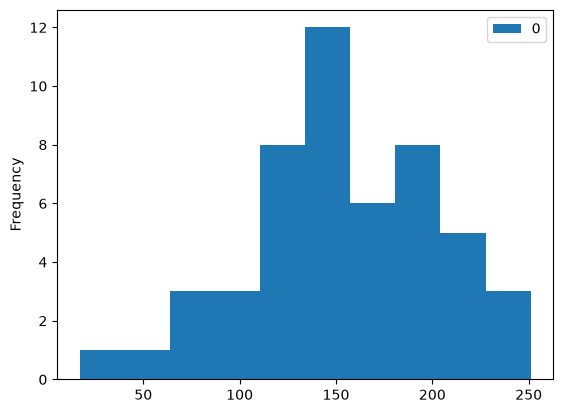

In [6]:
#histogram
import pandas as pd
pd.DataFrame(olcumler).plot.hist();

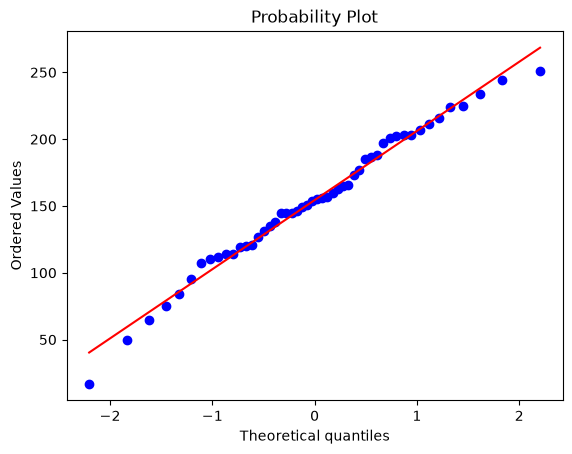

In [7]:
#qqplot
import pylab
stats.probplot(olcumler, dist="norm", plot=pylab)
pylab.show()

In [ ]:
#Shapiro-Wilks Testi

#H0: Örnek dağılımı ile teorik normal dağılım arasında ist. ol. anl. bir fark yoktur
#H1: Örnek dağılımı ile teorik normal dağılım arasında ist. ol. anl. bir fark vardır

In [ ]:
from scipy.stats import shapiro

print("T Hesap İstatistiği: " + str(shapiro(olcumler)[0]))
print("Hesaplanan P-value: " + str(shapiro(olcumler)[1]))
#p value, 0.05'den küçük değilse H0'ı reddetmiyoruz

T Hesap İstatistiği: 0.9853103897386145
Hesaplanan P-value: 0.7848671733155581


### Nonparametrik Tek Örneklem Testi

In [ ]:
#shapiro testinde p value değerinin negatif çıkıp H0'ı reddettiğimizi düşünelim, bu durumda başka yapabileceğimiz bir sürü testten biri de sign test

In [16]:
from statsmodels.stats.descriptivestats import sign_test

In [17]:
sign_test(olcumler, 170)

(np.float64(-7.0), np.float64(0.06490864707227217))

### Tek Örneklem Oran Testi

In [ ]:
#Oransal bir ifade test edilmek istenildiğinde kullanılır
#Bu test uygulayabilmemiz için gerekli varsayım der ki: eleman sayımız 30'dan büyük olmalıdır

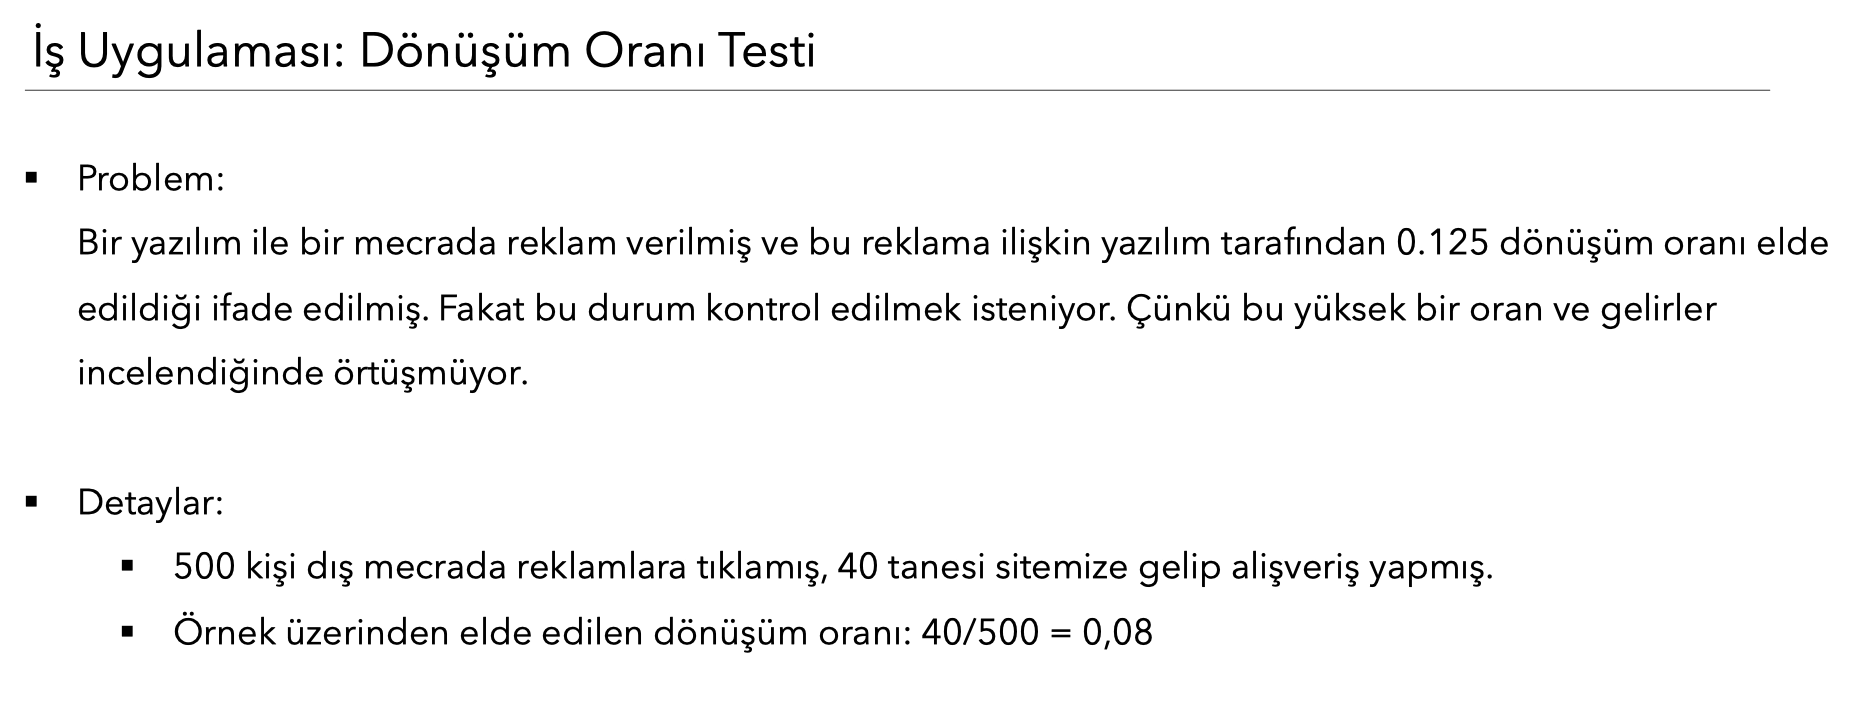
> Görüldüğü üzere çekilen örneklemdeki örnek sayısı 30'dan büyük

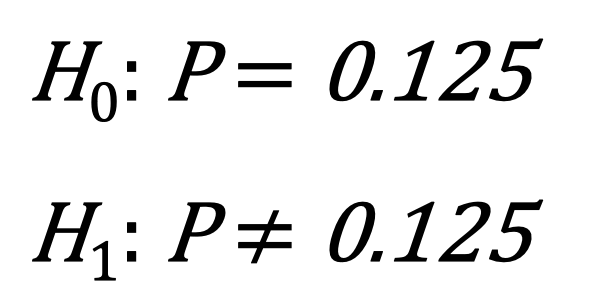

In [19]:
from statsmodels.stats.proportion import proportions_ztest

In [20]:
count = 40
value = 0.125
nobs = 500

In [ ]:
proportions_ztest(count, nobs, value)
#p value değerimiz 0.05'den küçük çıktığı için H0'ı reddederiz. Dönüşüm oran testimizin %95 güven ile 0.125 olmadığını söylemiş oluyoruz.

(np.float64(-3.7090151628513017), np.float64(0.0002080669689845979))

### Bağımsız İki Örneklem T Testi (AB Testi)

In [ ]:
#İki grup ortalaması arasında karşılaştırılma yapılmak istenildiğinde kullanılır.
#Örnek sayılarının farklılığına, varyanslarının homojen olup olmamasına göre farklı formüller kullanılır
#İki varsayımımız var: Normallik varsayımı ve varyans homojenliği

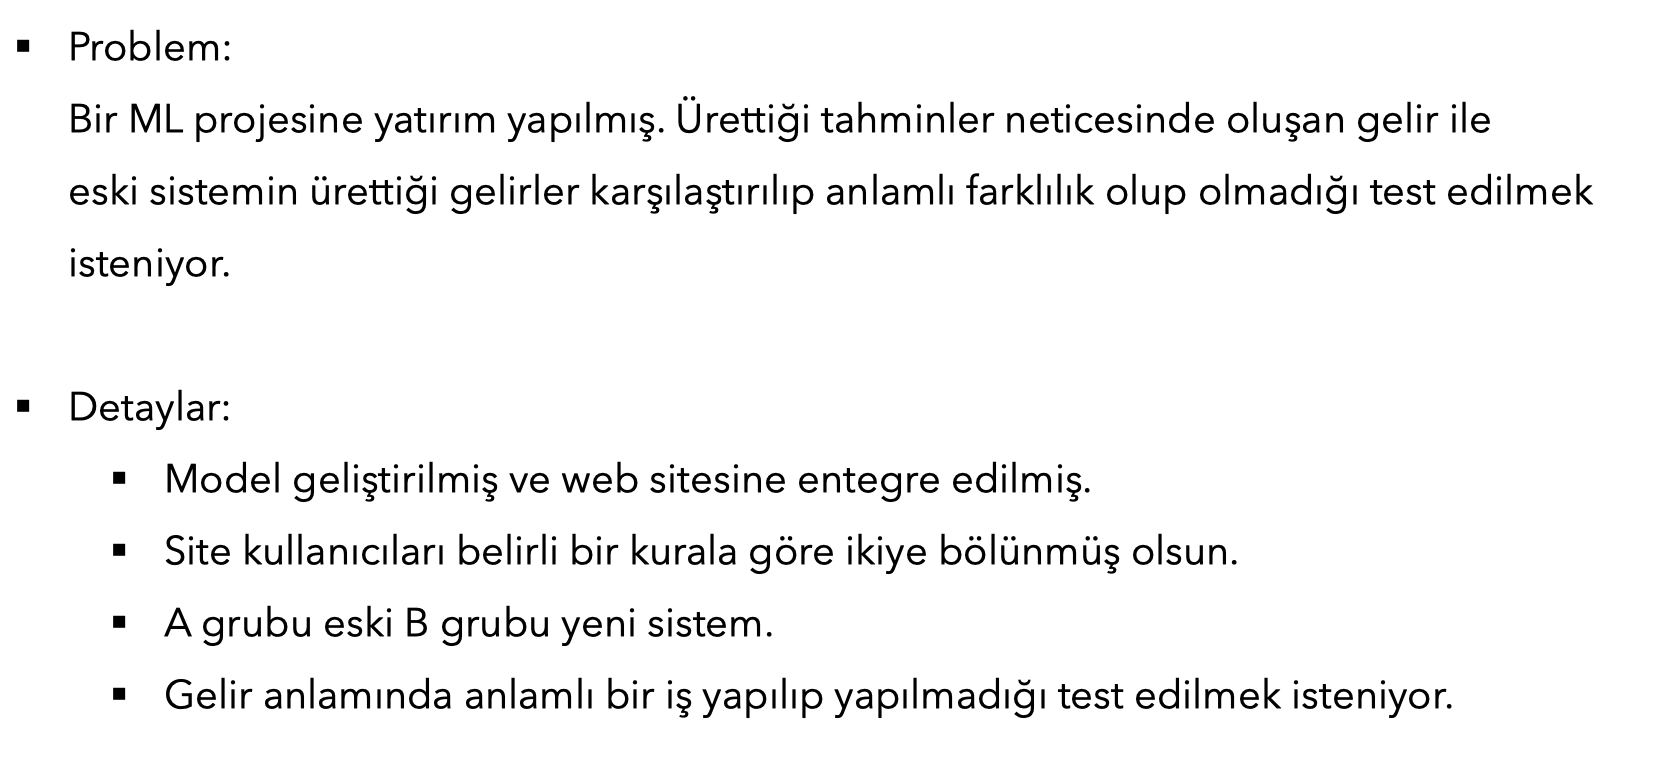

In [27]:
A = pd.DataFrame([30,27,21,27,29,30,20,20,27,32,35,22,24,23,25,27,23,27,23,
        25,21,18,24,26,33,26,27,28,19,25])

B = pd.DataFrame([37,39,31,31,34,38,30,36,29,28,38,28,37,37,30,32,31,31,27,
        32,33,33,33,31,32,33,26,32,33,29])


A_B = pd.concat([A, B], axis = 1)
A_B.columns = ["A","B"]

A_B.head()

,A,B
0,30,37
1,27,39
2,21,31
3,27,31
4,29,34


In [ ]:
import numpy as np
import pandas as pd

A = pd.DataFrame([30,27,21,27,29,30,20,20,27,32,35,22,24,23,25,27,23,27,23,
                  25,21,18,24,26,33,26,27,28,19,25])

B = pd.DataFrame([37,39,31,31,34,38,30,36,29,28,38,28,37,37,30,32,31,31,27,
                  32,33,33,33,31,32,33,26,32,33,29])

# Grupları oluştur
A.columns = ["gelir"]
A["GRUP"] = "A"

B.columns = ["gelir"]
B["GRUP"] = "B"

# Tüm verileri birleştir
AB = pd.concat([A, B], ignore_index=True)

print(AB.head())
print(AB.tail())


   gelir GRUP
0     30    A
1     27    A
2     21    A
3     27    A
4     29    A
    gelir GRUP
55     33    B
56     26    B
57     32    B
58     33    B
59     29    B


<Axes: xlabel='GRUP', ylabel='gelir'>

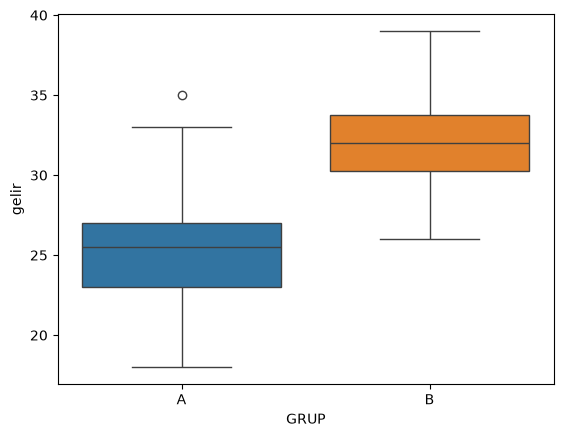

In [35]:
import seaborn as sns
sns.boxplot(x= "GRUP", y="gelir", hue = "GRUP", data= AB)

In [ ]:
test_istatistigi, p_value= stats.ttest_ind(A_B["A"],A_B["B"],equal_var=True)
print("Test istatistiği = %.4f, p değeri = %.4f" % (test_istatistigi, p_value))
#p-value, 0,05'den küçük olduğu için H0 hipotezi reddedilir, ortalamalar birbirine eşit değildir. Yeni sistem leğine bir sonuç çıkmıştır.

Test istatistiği = -7.0287, p değeri = 0.0000


#### Varsayım Testleri

In [36]:
#Normallik varsayımı

In [37]:
from scipy.stats import shapiro

In [ ]:
shapiro(A_B.A)
#H0 reddedilemez, normallik sağlanıyor

ShapiroResult(statistic=np.float64(0.978924370886716), pvalue=np.float64(0.796284803866721))

In [ ]:
shapiro(A_B.A)
#H0 reddedilemez, normallik sağlanıyor

ShapiroResult(statistic=np.float64(0.978924370886716), pvalue=np.float64(0.796284803866721))

In [42]:
#Varyans homojenliği varsayımı

#H0: Varyanslar homojendir
#H1: Varyanslar Homojen Değildir

In [57]:
stats.levene(A_B.A, A_B.B)
#p-value 0,05'den küçük değil, H0 reddedilemez. Varyanslar homojendir

LeveneResult(statistic=np.float64(1.1101802757158004), pvalue=np.float64(0.2964124900636549))

### Nonparametrik Bağımsız İki Örneklem T Testi

In [63]:
test_istatistigi, p_value = stats.mannwhitneyu(A_B["A"],A_B["B"])
print("Test istatistiği : %.4f, pvalue : %.4f" % (test_istatistigi, p_value))

Test istatistiği : 89.5000, pvalue : 0.0000


### Bağımlı İki Örneklem T Testi

In [64]:
#Bağımlı iki grup ortalaması arasında karşılaştırma yapılmak istenildiğindee kullanılır.
#Varsayımları iki adettir: Normallik ve varyans homojenliği

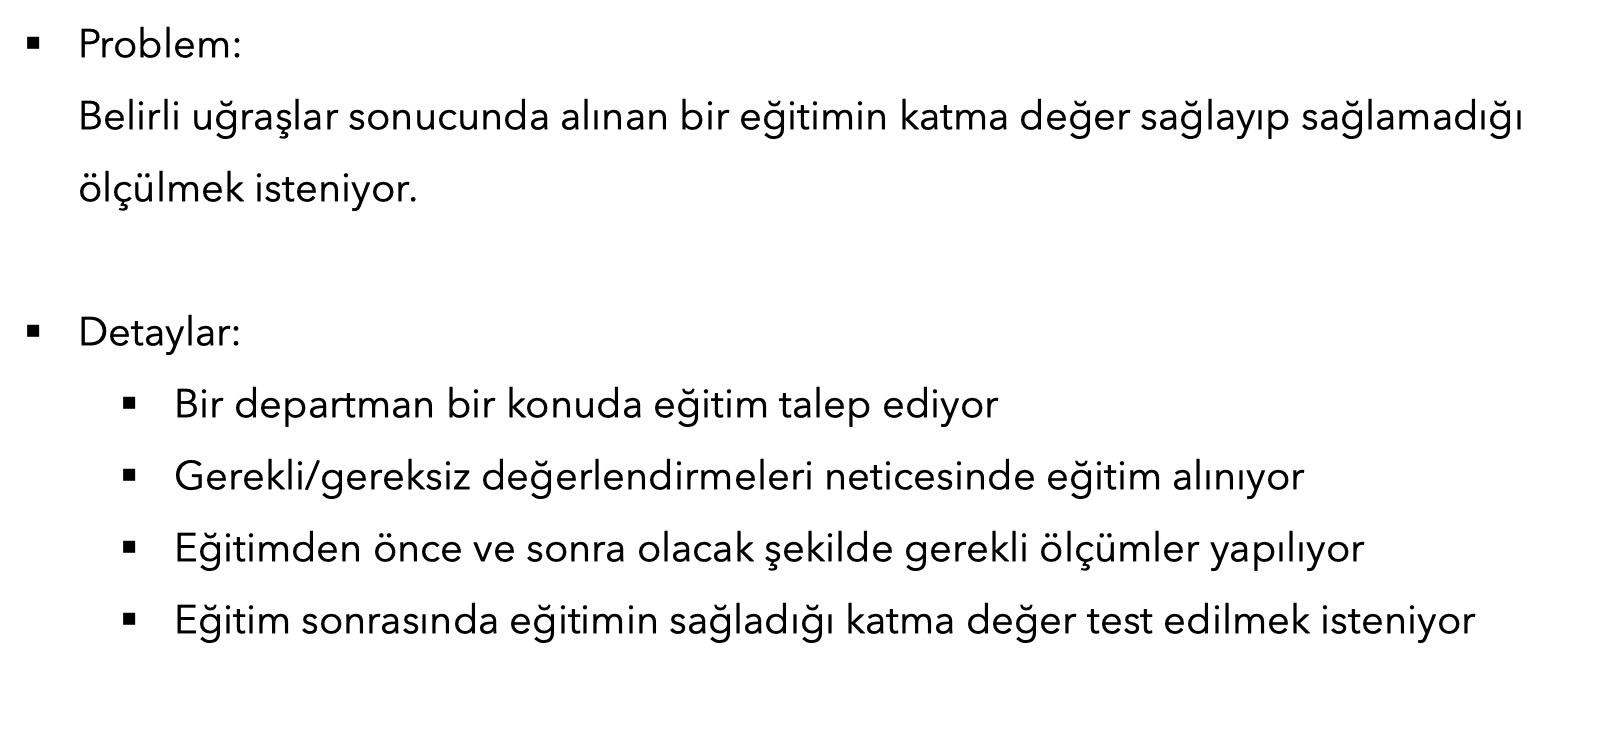

In [70]:
import numpy as np
import pandas as pd

oncesi = pd.DataFrame([123,119,119,116,123,123,121,120,117,118,121,121,123,119,
            121,118,124,121,125,115,115,119,118,121,117,117,120,120,
            121,117,118,117,123,118,124,121,115,118,125,115])

sonrasi = pd.DataFrame([118,127,122,132,129,123,129,132,128,130,128,138,140,130,
             134,134,124,140,134,129,129,138,134,124,122,126,133,127,
             130,130,130,132,117,130,125,129,133,120,127,123])

In [75]:
A_B = pd.concat([oncesi, sonrasi], axis = 1)
A_B.columns = ["ONCESI","SONRASI"]
A_B

,ONCESI,SONRASI
0,123,118
1,119,127
2,119,122
3,116,132
4,123,129
5,123,123
6,121,129
7,120,132
8,117,128
9,118,130


In [ ]:
oncesi = pd.DataFrame([123,119,119,116,123,123,121,120,117,118,121,121,123,119,
            121,118,124,121,125,115,115,119,118,121,117,117,120,120,
            121,117,118,117,123,118,124,121,115,118,125,115])

sonrasi = pd.DataFrame([118,127,122,132,129,123,129,132,128,130,128,138,140,130,
             134,134,124,140,134,129,129,138,134,124,122,126,133,127,
             130,130,130,132,117,130,125,129,133,120,127,123])

# Grupları oluştur
oncesi.columns = ["PERFORMANS"]
oncesi["GRUP"] = "ONCESI"

sonrasi.columns = ["PERFORMANS"]
sonrasi["GRUP"] = "SONRASI"

# Tüm verileri birleştir
AB = pd.concat([oncesi,sonrasi], ignore_index=True)

print(AB.head())
print(AB.tail())


   PERFORMANS    GRUP
0         123  ONCESI
1         119  ONCESI
2         119  ONCESI
3         116  ONCESI
4         123  ONCESI
    PERFORMANS     GRUP
75         129  SONRASI
76         133  SONRASI
77         120  SONRASI
78         127  SONRASI
79         123  SONRASI


<Axes: xlabel='GRUP', ylabel='PERFORMANS'>

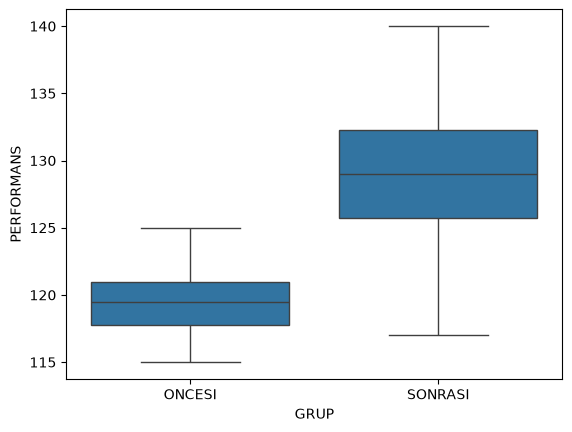

In [68]:
import seaborn as sns
sns.boxplot(data = AB, x = AB["GRUP"], y = AB["PERFORMANS"])

In [ ]:
test_istatistigi, p_value= stats.ttest_rel(A_B["ONCESI"],A_B["SONRASI"])
print("Test istatistiği : %.5f, p-value : %.5f" % (test_istatistigi, p_value))
#p-value 0.05'ten küçük olduğu için H0 hipotezi reddedilir. Yani eğitim öncesi ve sonrası performans ortalaması aynı değildir(%95 güvenilirlik ile).

Test istatistiği : -9.28153, p-value : 0.00000


 #### Varsayım Kontrolü

In [69]:
from scipy.stats import shapiro

In [79]:
shapiro(A_B["ONCESI"])

ShapiroResult(statistic=np.float64(0.954365128558809), pvalue=np.float64(0.10722012387565044))

In [80]:
shapiro(A_B["SONRASI"])
#ikiside p-value'dan küçük değil, H0'ı reddemeyiz. Normal dağılım gösterir ikiside (yaklaşık normal da olsa olur)

ShapiroResult(statistic=np.float64(0.9780089132317746), pvalue=np.float64(0.6159508884462558))

<Axes: xlabel='ONCESI', ylabel='Count'>

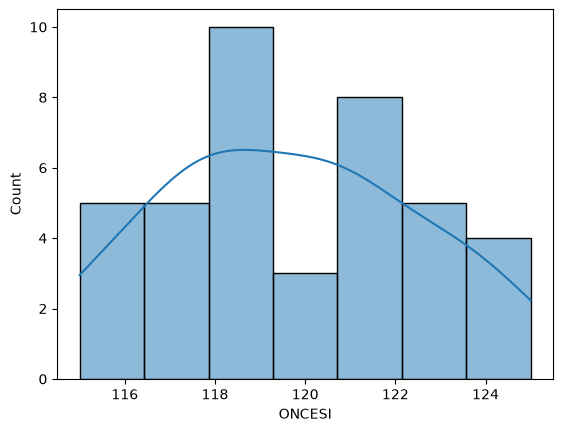

In [87]:
#histogram
import pandas as pd
sns.histplot(
    data=A_B,
    x="ONCESI",
    kde=True
)

<Axes: xlabel='SONRASI', ylabel='Count'>

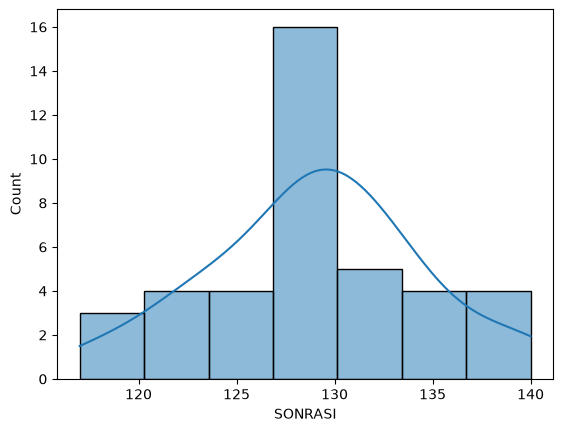

In [88]:
import pandas as pd
sns.histplot(
    data=A_B,
    x="SONRASI",
    kde=True
)

In [89]:
#Varyans homojenliği testi

In [ ]:
import scipy.stats as stats

In [ ]:
stats.levene(A_B["ONCESI"],A_B["SONRASI"])
#p-value değeri, 0.05'ten küçük. Dolayısıyla H0 hipotezi reddedilir. Yani varyans homojenliği göstermiyor.

LeveneResult(statistic=np.float64(8.31303288672351), pvalue=np.float64(0.005084451180737009))

In [91]:
#Böyle olduğu durumlarda ya outlier düzenleme işlemleri yapılır ya da bu varsayımı gözardı edeceğiz. Sağlanmış gibi devam edeceğiz

### Nonparametrik Bağımlı İki Örneklem T Testi

In [96]:
#Normal dağılım ve varyans homojenliği sağlanmazsa bunları uygulamalıyız

In [98]:
import scipy.stats as stats
stats.wilcoxon(A_B["ONCESI"],A_B["SONRASI"])

WilcoxonResult(statistic=np.float64(15.0), pvalue=np.float64(2.491492033374464e-07))

### İki Örneklem Oran Testi

In [99]:
#İki oran arasında karşılaştırma yapmak için kullanılır

In [ ]:
#İki grup içinde n>30 olmalı. Tek varsayımımız budur.

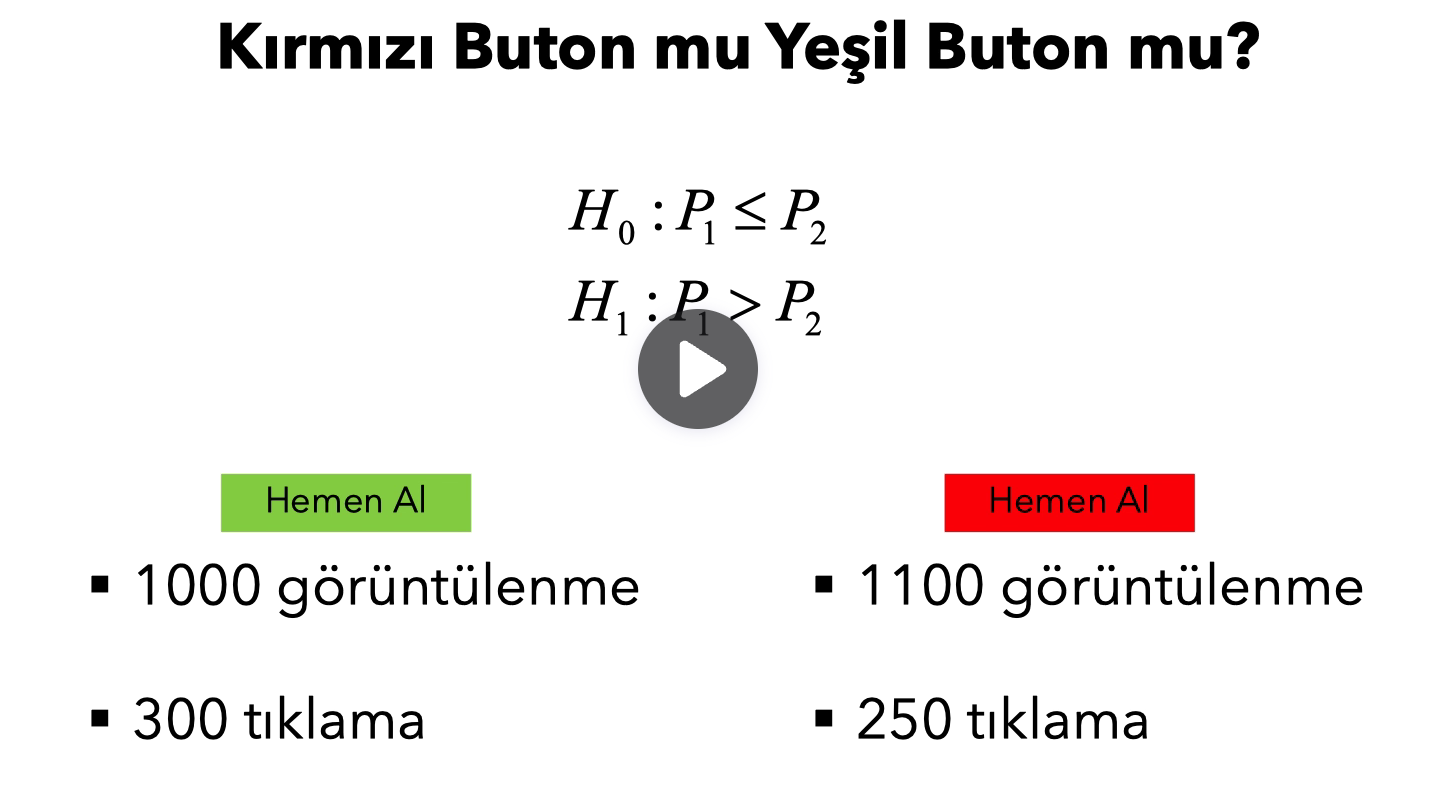

In [ ]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np

In [101]:
gözlem_sayilari = np.array([1000,1100])
basari_sayisi = np.array([300,250])
proportions_ztest(count = basari_sayisi, nobs = gözlem_sayilari)

(np.float64(3.7857863233209255), np.float64(0.0001532232957772221))

In [ ]:
#p-value değeri 0.05'den küçük olduğundan H0 reddedilir. Yeşil butonun leğine bir yönelim var.

### Varyans Analizi